# Sparse-feature overlap of adversarial suffixes (Jaccard similarity)

For each suffix source we take the top-K SAE features (by mean activation over prompts) and compute pairwise Jaccard similarity $J(A,B)=|A\cap B|/|A\cup B|$ between sources. Results are written to `results/jaccard/<attack>/<model>/`.

Features directory: ../data/sae_features/beast/mistral-7b
Output directory: ../results/jaccard/beast/mistral-7b
Top-K: 20
Selection method: mean
Active threshold: 0.0
Auto-suggest TOPK: True (override=True)

LOADING ALL SAE FEATURES

Found 15 feature files:
  Loading: beast_gemma_9b_sae_l19...
    ✓ Loaded 218 samples, 65536 features
  Loading: beast_llama_8b_base...
    ✓ Loaded 218 samples, 65536 features
  Loading: beast_mistral_7b_sae...
    ✓ Loaded 218 samples, 65536 features
  Loading: random_text_lowercase...
    ✓ Loaded 218 samples, 65536 features
  Loading: random_mixed_case...
    ✓ Loaded 218 samples, 65536 features
  Loading: beast_gemma_27b_sae_l34...
    ✓ Loaded 218 samples, 65536 features
  Loading: random_unicode_text...
    ✓ Loaded 218 samples, 65536 features
  Loading: random_text_numbers...
    ✓ Loaded 218 samples, 65536 features
  Loading: random_full_alphanumeric_symbols...
    ✓ Loaded 877 samples, 65536 features
  Loading: beast_gemma_2b_base...
    ✓ Loaded

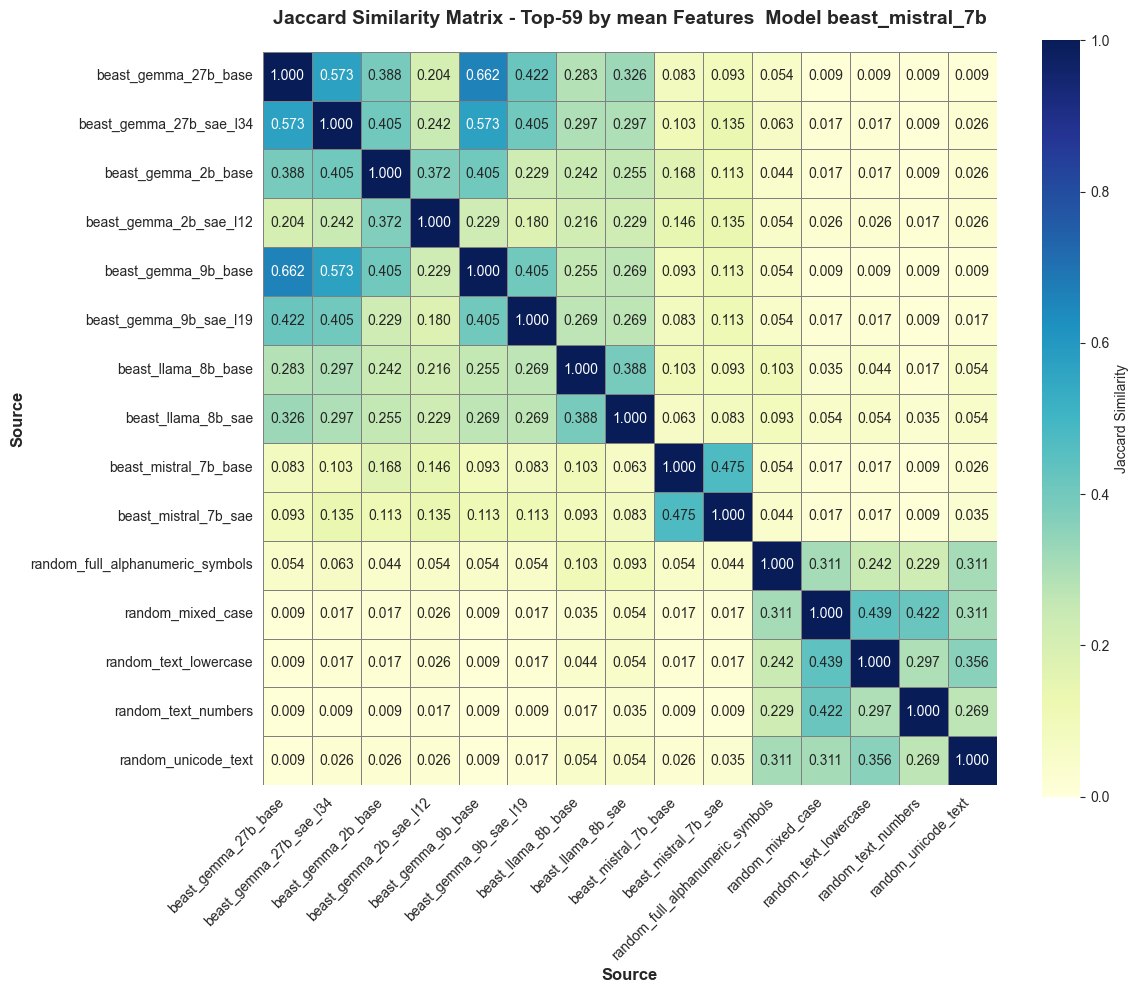


✓ Saved: ../results/jaccard/beast/mistral-7b/jaccard_similarity_top59_mean.png

EXPORTING RESULTS

✓ Saved Jaccard matrix: ../results/jaccard/beast/mistral-7b/jaccard_matrix_top59_mean.csv
✓ Saved active feature stats: ../results/jaccard/beast/mistral-7b/active_feature_stats_thr0.0_top59_mean.csv
✓ Saved top features: ../results/jaccard/beast/mistral-7b/top_features_top59_mean.json
✓ Saved overlap statistics: ../results/jaccard/beast/mistral-7b/overlap_statistics_top59_mean.json

✓ Analysis complete!


In [1]:
import pickle
import json
from pathlib import Path
from typing import List, Dict, Tuple, Set
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import pandas as pd
from itertools import combinations

# Set style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (14, 8)

# ============================================================================
# Configuration
# ============================================================================

class Config:
    # Input directory with saved SAE features
   # FEATURES_DIR = "../data/sae_features/beast/gemma-9b" # gemma
  #  FEATURES_DIR = "../data/sae_features/beast/llama-8b" # llama
    FEATURES_DIR = "../data/sae_features/beast/mistral-7b"  # mistral
   # FEATURES_DIR = "../data/sae_features/random/gemma-9b"  # random baseline
   

    # Output directory for analysis
    OUTPUT_DIR = "../results/jaccard/beast/mistral-7b"

    # Top-K selection
    TOP_K = 20  # Number of top features to select
    SELECTION_METHOD = "mean"  # Options: "variance", "mean", "both"

    # Active feature definition (for sparsity stats)
    ACTIVE_THRESHOLD = 0.0  # active if abs(x) > threshold; 0.0 means x != 0

    # Optional: auto-suggest TOP_K from median active features across sources
    AUTO_SUGGEST_TOPK_FROM_MEDIAN_ACTIVE = True
    AUTO_OVERRIDE_TOPK = True  # if True, will overwrite Config.TOP_K with suggested value


print(f"Features directory: {Config.FEATURES_DIR}")
print(f"Output directory: {Config.OUTPUT_DIR}")
print(f"Top-K: {Config.TOP_K}")
print(f"Selection method: {Config.SELECTION_METHOD}")
print(f"Active threshold: {Config.ACTIVE_THRESHOLD}")
print(f"Auto-suggest TOPK: {Config.AUTO_SUGGEST_TOPK_FROM_MEDIAN_ACTIVE} (override={Config.AUTO_OVERRIDE_TOPK})")

# ============================================================================
# Cell 3: Load All SAE Features
# ============================================================================

def load_all_features(features_dir: str) -> Dict[str, Dict]:
    """
    Load all SAE feature files from directory

    Returns:
        Dict mapping source name to loaded data
    """
    features_dir = Path(features_dir)
    all_features = {}

    # Find all pickle files
    pkl_files = list(features_dir.glob("*_sae_features.pkl"))

    if len(pkl_files) == 0:
        print(f"No pickle files found in {features_dir}")
        return {}

    print(f"Found {len(pkl_files)} feature files:")

    for pkl_file in pkl_files:
        # Extract source name from filename
        source_name = pkl_file.stem.replace("_sae_features", "")

        print(f"  Loading: {source_name}...")

        with open(pkl_file, "rb") as f:
            data = pickle.load(f)

        all_features[source_name] = data

        print(
            f"    ✓ Loaded {data['features'].shape[0]} samples, "
            f"{data['features'].shape[1]} features"
        )

    return all_features


# Load all features
print("\n" + "=" * 80)
print("LOADING ALL SAE FEATURES")
print("=" * 80 + "\n")

all_features = load_all_features(Config.FEATURES_DIR)

print(f"\n{'='*80}")
print(f"Loaded {len(all_features)} sources:")
for source_name in sorted(all_features.keys()):
    print(f"  - {source_name}")
print("=" * 80)

# ============================================================================
# Cell 4: Feature Selection + Active Feature Stats
# ============================================================================

def active_feature_counts(features: torch.Tensor, threshold: float = 0.0) -> torch.Tensor:
    """
    Count active features per sample.

    Active means abs(x) > threshold.
    features: [num_samples, num_features]
    returns:  [num_samples] counts
    """
    if threshold <= 0:
        active = features != 0
    else:
        active = features.abs() > threshold
    return active.sum(dim=1)


def select_top_k_by_variance(features: torch.Tensor, k: int) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Select top-k features by variance across samples
    """
    variances = features.var(dim=0)
    top_indices = variances.argsort(descending=True)[:k]
    top_values = variances[top_indices]
    return top_indices, top_values


def select_top_k_by_mean(features: torch.Tensor, k: int) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Select top-k features by mean activation across samples
    """
    means = features.mean(dim=0)
    top_indices = means.argsort(descending=True)[:k]
    top_values = means[top_indices]
    return top_indices, top_values


def select_top_k_combined(features: torch.Tensor, k: int) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """
    Select top-k features by combined score (mean * variance)
    """
    means = features.mean(dim=0)
    variances = features.var(dim=0)
    combined_score = means * variances

    top_indices = combined_score.argsort(descending=True)[:k]
    top_means = means[top_indices]
    top_vars = variances[top_indices]
    return top_indices, top_means, top_vars


# ============================================================================
# Cell 4.5: (Optional) Suggest TOP_K from median active counts across sources
# ============================================================================

if Config.AUTO_SUGGEST_TOPK_FROM_MEDIAN_ACTIVE and len(all_features) > 0:
    medians = []
    for s, d in all_features.items():
        counts = active_feature_counts(d["features"], threshold=Config.ACTIVE_THRESHOLD).to(torch.float32)
        medians.append(counts.median().item())

    suggested_k = int(round(float(np.median(medians)))) if len(medians) > 0 else Config.TOP_K
    print(f"\nSuggested TOP_K from median(active_medians_across_sources) = {suggested_k}")

    if Config.AUTO_OVERRIDE_TOPK:
        Config.TOP_K = max(1, suggested_k)
        print(f"✓ Overriding Config.TOP_K -> {Config.TOP_K}")

# ============================================================================
# Cell 5: Select Top-K Features for Each Source + Active Stats
# ============================================================================

print("\n" + "=" * 80)
print(f"SELECTING TOP-{Config.TOP_K} FEATURES FOR EACH SOURCE")
print(f"Method: {Config.SELECTION_METHOD}")
print("=" * 80)

top_features_by_source: Dict[str, Dict] = {}

for source_name, source_data in all_features.items():
    features = source_data["features"]
    print(source_name)
    print(features.shape)

    # --- Active feature stats per source ---
    counts = active_feature_counts(features, threshold=Config.ACTIVE_THRESHOLD).to(torch.float32)
    mean_active = counts.mean().item()
    median_active = counts.median().item()

    print(f"\n{source_name}:")
    print(
        f"  Active features per sample (threshold={Config.ACTIVE_THRESHOLD}): "
        f"mean={mean_active:.2f}, median={median_active:.2f}"
    )

    if Config.SELECTION_METHOD == "variance":
        top_indices, top_values = select_top_k_by_variance(features, Config.TOP_K)

        print(f"  Top-{Config.TOP_K} by variance:")
        print(f"    Max variance: {top_values[0].item():.6f}")
        print(f"    Min variance (in top-k): {top_values[-1].item():.6f}")
        print(f"    Mean variance (in top-k): {top_values.mean().item():.6f}")

        top_features_by_source[source_name] = {
            "method": "variance",
            "indices": top_indices,
            "values": top_values,
            "indices_set": set(top_indices.tolist()),
            "active_threshold": float(Config.ACTIVE_THRESHOLD),
            "active_mean_per_sample": float(mean_active),
            "active_median_per_sample": float(median_active),
        }

    elif Config.SELECTION_METHOD == "mean":
        top_indices, top_values = select_top_k_by_mean(features, Config.TOP_K)

        print(f"  Top-{Config.TOP_K} by mean activation:")
        print(f"    Max mean: {top_values[0].item():.6f}")
        print(f"    Min mean (in top-k): {top_values[-1].item():.6f}")
        print(f"    Average mean (in top-k): {top_values.mean().item():.6f}")

        top_features_by_source[source_name] = {
            "method": "mean",
            "indices": top_indices,
            "values": top_values,
            "indices_set": set(top_indices.tolist()),
            "active_threshold": float(Config.ACTIVE_THRESHOLD),
            "active_mean_per_sample": float(mean_active),
            "active_median_per_sample": float(median_active),
        }

    elif Config.SELECTION_METHOD == "both":
        top_indices, top_means, top_vars = select_top_k_combined(features, Config.TOP_K)

        print(f"  Top-{Config.TOP_K} by combined score (mean * variance):")
        print(f"    Max mean: {top_means[0].item():.6f}")
        print(f"    Max variance: {top_vars[0].item():.6f}")
        print(f"    Mean of means: {top_means.mean().item():.6f}")
        print(f"    Mean of variances: {top_vars.mean().item():.6f}")

        top_features_by_source[source_name] = {
            "method": "combined",
            "indices": top_indices,
            "means": top_means,
            "variances": top_vars,
            "indices_set": set(top_indices.tolist()),
            "active_threshold": float(Config.ACTIVE_THRESHOLD),
            "active_mean_per_sample": float(mean_active),
            "active_median_per_sample": float(median_active),
        }

    else:
        raise ValueError(f"Unknown SELECTION_METHOD: {Config.SELECTION_METHOD}")

print(f"\n{'='*80}")
print("✓ Feature selection complete")
print("=" * 80)

# ============================================================================
# Cell 6: Compute Jaccard Similarity
# ============================================================================

def jaccard_similarity(set1: Set, set2: Set) -> float:
    """
    Compute Jaccard similarity between two sets

    J(A, B) = |A ∩ B| / |A ∪ B|
    """
    if len(set1) == 0 and len(set2) == 0:
        return 1.0

    intersection = len(set1 & set2)
    union = len(set1 | set2)

    return intersection / union if union > 0 else 0.0


def compute_jaccard_matrix(top_features_dict: Dict[str, Dict]) -> Tuple[np.ndarray, List[str]]:
    """
    Compute pairwise Jaccard similarity matrix
    """
    source_names = sorted(top_features_dict.keys())
    n_sources = len(source_names)

    jaccard_matrix = np.zeros((n_sources, n_sources))

    for i, source_a in enumerate(source_names):
        for j, source_b in enumerate(source_names):
            set_a = top_features_dict[source_a]["indices_set"]
            set_b = top_features_dict[source_b]["indices_set"]
            jaccard_matrix[i, j] = jaccard_similarity(set_a, set_b)

    return jaccard_matrix, source_names


print("\n" + "=" * 80)
print("COMPUTING JACCARD SIMILARITY")
print("=" * 80)

jaccard_matrix, source_names = compute_jaccard_matrix(top_features_by_source)

print(f"\nJaccard Similarity Matrix ({len(source_names)}x{len(source_names)}):")
print("\nDiagonal (self-similarity): all should be 1.0")

# Print pairwise similarities
print("\nPairwise Jaccard Similarities:")
print(f"{'Source A':<20} {'Source B':<20} {'Jaccard':<10} {'Overlap':<10} {'Union'}")
print("-" * 70)

for i, source_a in enumerate(source_names):
    for j, source_b in enumerate(source_names):
        if i < j:
            set_a = top_features_by_source[source_a]["indices_set"]
            set_b = top_features_by_source[source_b]["indices_set"]

            overlap = len(set_a & set_b)
            union = len(set_a | set_b)
            jaccard = jaccard_matrix[i, j]

            print(f"{source_a:<20} {source_b:<20} {jaccard:<10.4f} {overlap:<10} {union}")

print("=" * 80)

# ============================================================================
# Cell 7: Visualize Jaccard Similarity Matrix
# ============================================================================

# Create output directory
Path(Config.OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(12, 10))

sns.heatmap(
    jaccard_matrix,
    mask=None,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    square=True,
    xticklabels=source_names,
    yticklabels=source_names,
    cbar_kws={"label": "Jaccard Similarity"},
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="gray",
)

plt.title(
    f"Jaccard Similarity Matrix - Top-{Config.TOP_K} by {Config.SELECTION_METHOD} Features  Model {Config.OUTPUT_DIR.split('/')[-1]}",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Source", fontsize=12, fontweight="bold")
plt.ylabel("Source", fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

output_file = Path(Config.OUTPUT_DIR) / f"jaccard_similarity_top{Config.TOP_K}_{Config.SELECTION_METHOD}.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"\n✓ Saved: {output_file}")

# ============================================================================
# Cell 11: Export Results to CSV and JSON (incl. active stats)
# ============================================================================

print("\n" + "=" * 80)
print("EXPORTING RESULTS")
print("=" * 80)

# Export Jaccard matrix to CSV
jaccard_df = pd.DataFrame(jaccard_matrix, index=source_names, columns=source_names)

csv_file = Path(Config.OUTPUT_DIR) / f"jaccard_matrix_top{Config.TOP_K}_{Config.SELECTION_METHOD}.csv"
jaccard_df.to_csv(csv_file)
print(f"\n✓ Saved Jaccard matrix: {csv_file}")

# Export active feature stats per source
active_stats_rows = []
for s in sorted(top_features_by_source.keys()):
    active_stats_rows.append(
        {
            "source": s,
            "active_threshold": top_features_by_source[s].get("active_threshold", float(Config.ACTIVE_THRESHOLD)),
            "active_mean_per_sample": top_features_by_source[s].get("active_mean_per_sample", None),
            "active_median_per_sample": top_features_by_source[s].get("active_median_per_sample", None),
            "top_k": Config.TOP_K,
            "selection_method": Config.SELECTION_METHOD,
        }
    )

active_stats_df = pd.DataFrame(active_stats_rows).sort_values("source")
active_csv = (
    Path(Config.OUTPUT_DIR)
    / f"active_feature_stats_thr{Config.ACTIVE_THRESHOLD}_top{Config.TOP_K}_{Config.SELECTION_METHOD}.csv"
)
active_stats_df.to_csv(active_csv, index=False)
print(f"✓ Saved active feature stats: {active_csv}")

# Export top features for each source
top_features_export = {}
for source_name, top_info in top_features_by_source.items():
    top_features_export[source_name] = {
        "method": top_info["method"],
        "top_k": Config.TOP_K,
        "indices": [int(i) for i in top_info["indices"].tolist()],
        "active_threshold": float(top_info.get("active_threshold", Config.ACTIVE_THRESHOLD)),
        "active_mean_per_sample": float(top_info.get("active_mean_per_sample", float("nan"))),
        "active_median_per_sample": float(top_info.get("active_median_per_sample", float("nan"))),
    }

    if Config.SELECTION_METHOD == "variance":
        top_features_export[source_name]["variances"] = [float(v) for v in top_info["values"].tolist()]
    elif Config.SELECTION_METHOD == "mean":
        top_features_export[source_name]["means"] = [float(v) for v in top_info["values"].tolist()]
    elif Config.SELECTION_METHOD == "both":
        top_features_export[source_name]["means"] = [float(v) for v in top_info["means"].tolist()]
        top_features_export[source_name]["variances"] = [float(v) for v in top_info["variances"].tolist()]

json_file = Path(Config.OUTPUT_DIR) / f"top_features_top{Config.TOP_K}_{Config.SELECTION_METHOD}.json"
with open(json_file, "w") as f:
    json.dump(top_features_export, f, indent=2)

print(f"✓ Saved top features: {json_file}")

# Export overlap statistics
overlap_stats = {
    "config": {
        "top_k": Config.TOP_K,
        "selection_method": Config.SELECTION_METHOD,
        "num_sources": len(source_names),
        "active_threshold": float(Config.ACTIVE_THRESHOLD),
    },
    "active_feature_stats_per_source": {
        s: {
            "active_mean_per_sample": float(top_features_by_source[s].get("active_mean_per_sample", float("nan"))),
            "active_median_per_sample": float(top_features_by_source[s].get("active_median_per_sample", float("nan"))),
        }
        for s in source_names
    },
    "pairwise_similarities": {},
}

for i, source_a in enumerate(source_names):
    for j, source_b in enumerate(source_names):
        if i < j:
            set_a = top_features_by_source[source_a]["indices_set"]
            set_b = top_features_by_source[source_b]["indices_set"]

            overlap_stats["pairwise_similarities"][f"{source_a}_vs_{source_b}"] = {
                "jaccard": float(jaccard_matrix[i, j]),
                "overlap": len(set_a & set_b),
                "union": len(set_a | set_b),
                "only_in_a": len(set_a - set_b),
                "only_in_b": len(set_b - set_a),
            }

if len(source_names) > 1:
    all_sets = [top_features_by_source[s]["indices_set"] for s in source_names]
    common_features = set.intersection(*all_sets)
    all_features_union = set.union(*all_sets)

    overlap_stats["global"] = {
        "total_unique_features": len(all_features_union),
        "common_to_all": len(common_features),
        "common_features_list": sorted(list(common_features)),
    }

stats_file = Path(Config.OUTPUT_DIR) / f"overlap_statistics_top{Config.TOP_K}_{Config.SELECTION_METHOD}.json"
with open(stats_file, "w") as f:
    json.dump(overlap_stats, f, indent=2)

print(f"✓ Saved overlap statistics: {stats_file}")

print(f"\n{'='*80}")
print("✓ Analysis complete!")
print("=" * 80)


## Interpretation

To test whether suffixes optimised against SAE-augmented models still resemble the adversarial inputs produced against the baseline models, we compare which SAE features they activate, using the SAE at the same layer where the model was attacked. For one model from each family (Mistral-7B, Llama-3.1-8B, Gemma-2-9B) we compute the Jaccard similarity between the top-K activated features of inputs carrying a base-model suffix and inputs carrying an SAE-model suffix, across all source models in the study. K is the median number of active features over the 218 HarmBench prompts (it is encoded in the `topK` part of every output file name). SAE widths are 16,384, 65,536 and 65,536 for Gemma-2-9B, Llama-3.1-8B and Mistral-7B respectively. Random-text suffixes (`random_*`) serve as a baseline.

**Findings.** For Llama and Mistral, suffixes optimised against the SAE model are closest in feature space to the suffixes optimised against the corresponding base model. Gemma does not follow this rule, but features from all Gemma models are close to each other regardless of configuration. Adversarial suffixes overlap far more with each other than with random text (paper, Appendix D).

**How to run.** Set `Config.FEATURES_DIR` to one of the folders under `data/sae_features/` and `Config.OUTPUT_DIR` to the matching folder under `results/jaccard/`. The feature pickles are large (~6 GB in total) and are not tracked in git — see `data/README.md`.